# Imports

In [2]:
import numpy as np
import pandas as pd
import solarpy as sp
import datetime as dt

from scipy.constants import h, c, k
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

from colour.plotting import *

%matplotlib inline
%config InlineBackend.figure_format='retina'
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Circle, Rectangle
from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition, mark_inset)

# Datasets

In [3]:
# sun radiation spectral quantities from "Preetham et al. - A Practical Analytic Model for Daylight (Appendix A.6, Table 2)"
data0 = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/S0.txt')
data1 = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/S1.txt')
data2 = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/S2.txt')
data3 = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/SUN.txt')

lam = data0[:,0] # wavelength spectrum

# sun radiation mean spectral radiant power (wavelength (nm, ?))
S0  = data0[:,1] # scattering 0
S1  = data1[:,1] # scattering 1
S2  = data2[:,1] # scattering 2
SUN  = data3[:,1]

# photopic limunosity from www.cvrl.org, "CIE Photopic V(λ) modified by Judd (1951) and Vos (1978) [also known as CIE VM(λ)]", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
photopic = pd.read_csv('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/vljve.csv',skiprows=0,na_values = ['0'])
photopic_array = photopic.to_numpy()
photopic_V = photopic_array[:,1]

# scotopic limunosity from www.cvrl.org, "CIE (1951) Scotopic V'(λ)", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
scotopic = pd.read_csv('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/scvle.csv',skiprows=0,na_values = ['0'])
scotopic_array = scotopic.to_numpy()
scotopic_V = scotopic_array[:,1]

# the CIE colour matching function for 380 - 780 nm in 10 nm intervals
cmf = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/cie-cmf.txt', usecols=(1,2,3))

# City - Latitude Dictionaries

In [4]:
latitude_city = {39.9: "Ankara",
                 55.7: "Moscow",
                 52  : "Berlin",
                 51.5: "London",
                 41  : "Istanbul",
                 32.8: "Tripoli",
                 30  : "Cairo",
                 25  : "Sicily",
                -33.9: "Cape Town"}

city_latitude = {"Ankara"   : 39.9,
                 "Moscow"   : 55.7,
                 "Berlin"   : 52,
                 "London"   : 51.5,
                 "Istanbul" : 41,
                 "Tripoli"  : 32.8,
                 "Cairo"    : 30,
                 "Sicily"   : 25,
                 "Cape Town":-33.9}

# Functions

In [8]:
def planck(lam, T):
    
    lam_m = lam * 1e-9
    fac = h * c / (lam_m * k * T)
    intensity = 2 * h * c**2 / (lam_m**5 * (np.exp(fac) - 1))
    
    return intensity


# matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
A1 = [[ 0.1787,-1.4630],
      [-0.3554, 0.4275],
      [-0.0227, 5.3251],
      [ 0.1206,-2.5771],
      [-0.0670, 0.3703]]
    
A2 = [[-0.0193,-0.2592],
      [-0.0665, 0.0008],
      [-0.0004, 0.2125],
      [-0.0641,-0.8989],
      [-0.0033, 0.0452]]
    
A3 = [[-0.0167,-0.2608],
      [-0.0950, 0.0092],
      [-0.0079, 0.2102],
      [-0.0441,-1.6537],
      [-0.0109, 0.0529]]

xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
             [-0.0290, 0.0638,-0.0320, 0.0039],
             [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
             [-0.0421, 0.0897,-0.0415, 0.0052],
             [ 0.1535,-0.2676, 0.0667, 0.2669]]


def xyz_from_xy(x, y):
    
    return np.array((x, y, 1-x-y))

class ColourSystem:
    
    # the CIE colour matching function for 380 - 780 nm in 10 nm intervals
    # cmf = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/cie-cmf.txt', usecols=(1,2,3))
        
    def __init__(self, red, green, blue, white):
        
        # chromaticities
        self.red, self.green, self.blue = red, green, blue
        self.white = white
        
        # the chromaticity matrix (rgb -> xyz) and its inverse
        self.M = np.vstack((self.red, self.green, self.blue)).T 
        self.MI = np.linalg.inv(self.M)
        
        # white scaling array
        self.wscale = self.MI.dot(self.white)
        
        # xyz -> rgb transformation matrix
        self.T = self.MI / self.wscale[:, np.newaxis]
    
    def xyz_to_rgb(self, xyz, out_fmt=None):
        
        rgb = self.T.dot(xyz)
        
        if np.any(rgb < 0):
            # we're not in the RGB gamut: approximate by desaturating
            w = - np.min(rgb)
            rgb += w
            
        if not np.all(rgb == 0):
            # normalize the rgb vector
            rgb /= np.max(rgb)
        
        if out_fmt == 'html':
            return self.rgb_to_hex(rgb)
        
        return rgb
        
    def rgb_to_hex(self, rgb):
        
        hex_rgb = (255*rgb).astype(int)
        
        return '#{:02x}{:02x}{:02x}'.format(*hex_rgb)

    def spec_to_xyz(self, spec):
        
        XYZ = np.sum(spec[:, np.newaxis] * cmf, axis=0)
        den = np.sum(XYZ)
        if den == 0.:
            return XYZ
        
        return XYZ / den
    
    def spec_to_rgb(self, spec, out_fmt=None):
        
        xyz = self.spec_to_xyz(spec)
        
        return self.xyz_to_rgb(xyz, out_fmt)


illuminant_D65 = xyz_from_xy(0.3127, 0.3291)

cs_hdtv = ColourSystem(red   = xyz_from_xy(0.67, 0.33),
                       green = xyz_from_xy(0.21, 0.71),
                       blue  = xyz_from_xy(0.15, 0.06),
                       white = illuminant_D65)

cs_smpte = ColourSystem(red   = xyz_from_xy(0.63, 0.34),
                        green = xyz_from_xy(0.31, 0.595),
                        blue  = xyz_from_xy(0.155,0.070),
                        white = illuminant_D65)

cs_srgb = ColourSystem(red   = xyz_from_xy(0.64, 0.33),
                       green = xyz_from_xy(0.30, 0.60),
                       blue  = xyz_from_xy(0.15, 0.06),
                       white = illuminant_D65)


cs = cs_hdtv # choose color matching system (cs_hdtv, cs_smpte, cs_srgb)


def vision_throughout_the_day(date, latitude, altitude, turbidity, theta_viewer, phi_viewer):
    
    # the observer's viewing angle
    theta_v = theta_viewer*(pi/180)
    phi_v   = phi_viewer*(pi/180)
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    T_vector = [turbidity**2, turbidity, 1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    for i in range(144):
    
        m = 10*i
        
        theta_s = sp.theta_z(date + dt.timedelta(minutes=m), latitude)
        phi_s = sp.solar_azimuth(date + dt.timedelta(minutes=m), latitude)
        
        gamma = np.arccos(np.cos(theta_v)*np.cos(theta_s) + np.sin(theta_v)*np.cos(phi_v)*np.sin(theta_s)*np.cos(phi_s) + np.sin(theta_v)*np.sin(phi_v)*np.sin(theta_s)*np.sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(np.pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*np.tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*np.exp(Y_coefficient[1]/np.cos(theta_v))) * (1+Y_coefficient[2]*np.exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(np.cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*np.exp(Y_coefficient[1])) * (1+Y_coefficient[2]*np.exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(np.cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*np.exp(x_coefficient[1]/np.cos(theta_v))) * (1+x_coefficient[2]*np.exp(x_coefficient[3]*gamma) + x_coefficient[4]*(np.cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*np.exp(x_coefficient[1])) * (1+x_coefficient[2]*np.exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(np.cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*np.exp(y_coefficient[1]/np.cos(theta_v))) * (1+y_coefficient[2]*np.exp(y_coefficient[3]*gamma) + y_coefficient[4]*(np.cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*np.exp(y_coefficient[1])) * (1+y_coefficient[2]*np.exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(np.cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515 - 1.7703*x + 5.9114*y) / (0.0241 + 0.2562*x - 0.7341*y)
        M2 = (0.0300 - 31.4424*x + 30.0717*y) / (0.0241 + 0.2562*x - 0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        #for i in range(len(SD)):
        #    if SD[i] < 0:
        #        SD[i] = S0[i]
        #    else: pass
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V   
        
        vision_sc.append(sum(scotopic_vision))
        vision_pc.append(sum(photopic_vision))
        vision.append((sum(scotopic_vision)+sum(photopic_vision)))
        
    #time_scale = [i/60 for i in range(0,1440,10)]
    time_scale = [date + dt.timedelta(minutes=i) for i in range(0, 6*10*24, 10)]
    
    return time_scale, vision_sc, vision_pc, vision



def vision_at_a_moment(moment, latitude, altitude, turbidity, theta_viewer, phi_viewer):
    
    # the observer's viewing angle
    theta_v = theta_viewer*(np.pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v = phi_viewer*(np.pi/180) # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
        
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
        
    T_vector = [turbidity**2, turbidity, 1]
    
    theta_s = sp.theta_z(moment, latitude)
    phi_s = sp.solar_azimuth(moment, latitude)
    
    gamma = np.arccos(np.cos(theta_v)*np.cos(theta_s) + np.sin(theta_v)*np.cos(phi_v)*np.sin(theta_s)*np.cos(phi_s) + np.sin(theta_v)*np.sin(phi_v)*np.sin(theta_s)*np.sin(phi_s))
    
    Chi = (4/9 - turbidity/120)*(np.pi - 2*theta_s)
    Yz = (4.0453*turbidity - 4.9710)*np.tan(Chi) - 0.2155*turbidity + 2.4192
    
    theta_s_vector = [theta_s**3, theta_s**2, theta_s, 1]
    
    xz = np.dot(T_vector, xz_matrix)
    xz = np.dot(xz, theta_s_vector)
    
    yz = np.dot(T_vector, yz_matrix)
    yz = np.dot(yz, theta_s_vector)
    
    
    FY_theta_gamma = (1 + Y_coefficient[0]*np.exp(Y_coefficient[1]/np.cos(theta_v))) * (1+Y_coefficient[2]*np.exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(np.cos(gamma))**2)
    FY_0_theta_s = (1 + Y_coefficient[0]*np.exp(Y_coefficient[1])) * (1+Y_coefficient[2]*np.exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(np.cos(theta_s))**2)
        
    Fx_theta_gamma = (1 + x_coefficient[0]*np.exp(x_coefficient[1]/np.cos(theta_v))) * (1+x_coefficient[2]*np.exp(x_coefficient[3]*gamma) + x_coefficient[4]*(np.cos(gamma))**2)
    Fx_0_theta_s = (1 + x_coefficient[0]*np.exp(x_coefficient[1])) * (1+x_coefficient[2]*np.exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(np.cos(theta_s))**2)
        
    Fy_theta_gamma = (1 + y_coefficient[0]*np.exp(y_coefficient[1]/np.cos(theta_v))) * (1+y_coefficient[2]*np.exp(y_coefficient[3]*gamma) + y_coefficient[4]*(np.cos(gamma))**2)
    Fy_0_theta_s = (1 + y_coefficient[0]*np.exp(y_coefficient[1])) * (1+y_coefficient[2]*np.exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(np.cos(theta_s))**2)
    
    Y = Yz*(FY_theta_gamma / FY_0_theta_s)
    x = xz*(Fx_theta_gamma / Fx_0_theta_s)
    y = yz*(Fy_theta_gamma / Fy_0_theta_s)
    
    M1 = (-1.3515 - 1.7703*x + 5.9114*y) / (0.0241 + 0.2562*x - 0.7341*y)
    M2 = (0.0300 - 31.4424*x + 30.0717*y) / (0.0241 + 0.2562*x - 0.7341*y)
    
    SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2) # the relative spectral radiant power
    
    #for i in range(len(SD)):
    #    if SD[i] < 0:
    #        SD[i] = S0[i]
    #    else: pass
    
    scotopic_vision = SD * scotopic_V
    photopic_vision = SD * photopic_V
    
    return SD, scotopic_vision, photopic_vision



def sky_view(date, latitude, altitude, turbidity, theta_viewer, phi_viewer, spectrum, size):
    
    # the observer's viewing angle
    theta_v = theta_viewer*(pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v = phi_viewer*(pi/180) # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
    

    Y_coefficient = np.dot(A1, [turbidity, 1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity, 1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity, 1]) # [yy, yy, yy, yy, yy]
     
    T_vector = [turbidity**2, turbidity, 1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    fig, ax = plt.subplots(figsize=size)
    for i in range(144):
    
        m = 10*i
        
        theta_s = sp.theta_z(date + dt.timedelta(minutes=m), latitude)
        phi_s = sp.solar_azimuth(date + dt.timedelta(minutes=m), latitude)
        
        gamma = np.arccos(np.cos(theta_v)*np.cos(theta_s) + np.sin(theta_v)*np.cos(phi_v)*np.sin(theta_s)*np.cos(phi_s) + np.sin(theta_v)*np.sin(phi_v)*np.sin(theta_s)*np.sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*np.exp(Y_coefficient[1]/np.cos(theta_v))) * (1+Y_coefficient[2]*np.exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(np.cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*np.exp(Y_coefficient[1])) * (1+Y_coefficient[2]*np.exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(np.cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*np.exp(x_coefficient[1]/np.cos(theta_v))) * (1+x_coefficient[2]*np.exp(x_coefficient[3]*gamma) + x_coefficient[4]*(np.cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*np.exp(x_coefficient[1])) * (1+x_coefficient[2]*np.exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(np.cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*np.exp(y_coefficient[1]/np.cos(theta_v))) * (1+y_coefficient[2]*np.exp(y_coefficient[3]*gamma) + y_coefficient[4]*(np.cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*np.exp(y_coefficient[1])) * (1+y_coefficient[2]*np.exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(np.cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V   
        
        # plot the desired spectrum
        if   spectrum == 'SD'      : html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
        elif spectrum == 'scotopic': html_rgb = cs.spec_to_rgb(scotopic_vision, out_fmt='html')
        elif spectrum == 'photopic': html_rgb = cs.spec_to_rgb(photopic_vision, out_fmt='html')
        elif spectrum == 'total'   : html_rgb = cs.spec_to_rgb(scotopic_vision+photopic_vision, out_fmt='html')
        else: print("Choose the spectrum!")
        
        x_coordinate, y_coordinate = i%6, -(i//6)
        #patch = Circle(xy=(x_coordinate,y_coordinate*2), radius=0.5, fc=html_rgb)
        patch = Rectangle(xy=(x_coordinate,y_coordinate*2), width=0.98, height=1.8, fc=html_rgb)
        ax.add_patch(patch)
        
        seconds = dt.timedelta(minutes=m).seconds//60 # H:M formatter
        minutes = seconds//60
        seconds %= 60
        ax.annotate("%02i:%02i"%(minutes,seconds), xy=(x_coordinate,y_coordinate*2), xytext=(x_coordinate+0.35,y_coordinate*2+0.5), color='black')
        
    ax.set_xlim(-0.1, 6.07)
    ax.set_ylim(-47, 3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor('white')
    
    #ax.set_aspect("equal")
    
    plt.title("View for the "+spectrum+" spectrum on "+str(date.day)+"."+str(date.month)+"."+str(date.year)+", in "+latitude_city[latitude]+".", fontsize=15)
    
    plt.show()
    #fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/Sky_View/SkyView_"+latitude_city[latitude]+"_"+spectrum+".png", format='png', bbox_inches='tight')

    return print("View for the "+spectrum+" spectrum on "+str(date.day)+"."+str(date.month)+"."+str(date.year)+".")


def panoramic_sky_view(time, city, altitude, turbidity, theta_range_viewer, phi_range_viewer):
    
    latitude = city_latitude[city]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
 
    T_vector = [turbidity**2, turbidity, 1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    patch_color = []
    
    theta_difference = abs(theta_range_viewer[1] - theta_range_viewer[0])
    phi_difference = abs(phi_range_viewer[1] - phi_range_viewer[0])

    tt = theta_range_viewer[0]
    angle = []
    for i in range(theta_difference+1):
        pp = phi_range_viewer[0]
        for j in range(phi_difference+1):
            angle.append((tt,pp))
            pp += 1
        tt += 1
    
    n = (theta_difference + 1) * (phi_difference + 1)
    
    for i in range(n):
        
        theta_v = angle[i][0]*(np.pi/180)
        phi_v = angle[i][1]*(np.pi/180)
        
        theta_s = sp.theta_z(time, latitude)
        phi_s = sp.solar_azimuth(time, latitude)
        
        gamma = np.arccos(np.cos(theta_v)*np.cos(theta_s) + np.sin(theta_v)*np.cos(phi_v)*np.sin(theta_s)*np.cos(phi_s) + np.sin(theta_v)*np.sin(phi_v)*np.sin(theta_s)*np.sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(np.pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*np.tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3, theta_s**2, theta_s, 1]
        
        xz = np.dot(T_vector, xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector, yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*np.exp(Y_coefficient[1]/np.cos(theta_v))) * (1+Y_coefficient[2]*np.exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(np.cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*np.exp(Y_coefficient[1])) * (1+Y_coefficient[2]*np.exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(np.cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*np.exp(x_coefficient[1]/np.cos(theta_v))) * (1+x_coefficient[2]*np.exp(x_coefficient[3]*gamma) + x_coefficient[4]*(np.cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*np.exp(x_coefficient[1])) * (1+x_coefficient[2]*np.exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(np.cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*np.exp(y_coefficient[1]/np.cos(theta_v))) * (1+y_coefficient[2]*np.exp(y_coefficient[3]*gamma) + y_coefficient[4]*(np.cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*np.exp(y_coefficient[1])) * (1+y_coefficient[2]*np.exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(np.cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V
        
        html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
        patch_color.append(html_rgb)
    
    return patch_color

# Figure 1

Optimal parameters for fitted function = 3.86259199741e-05 0.00755979237423 -121.043193422 333.623674065 68.453872952



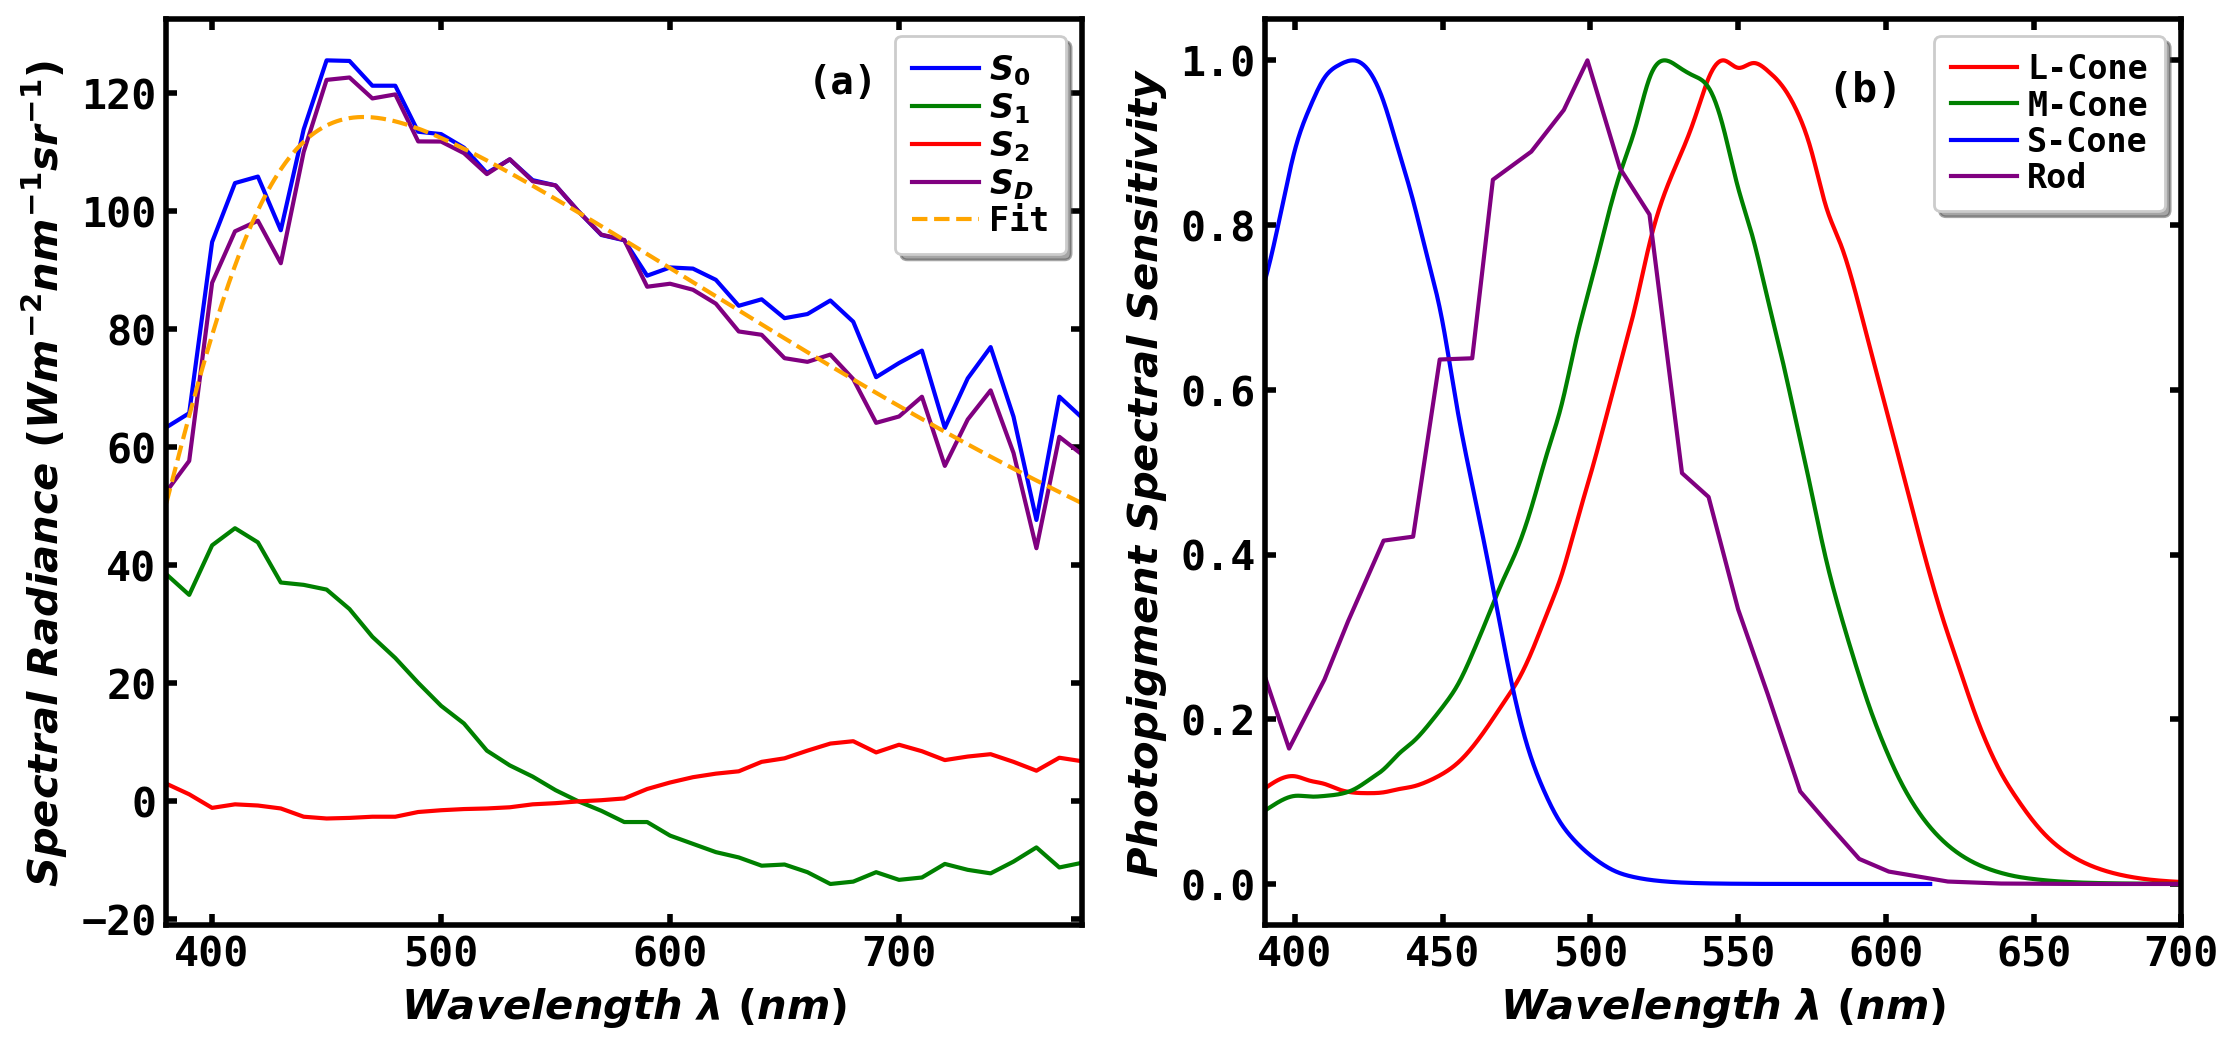

In [10]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(13, 6), dpi=100)
fig.set_facecolor("white")
plt.rc(group="font", family="monospace", weight="bold", size=15)
plt.rc(group="lines", linewidth=1.5)
plt.rc(group="axes", linewidth=2)


#---------------------- PANEL (a) ----------------------#
def fit_function(x, A, alpha, B, beta, sigma):
    
    return A * x**3 / (np.exp(alpha * x) - 1) + B * np.exp(-((x - beta)/sigma)**2)

time = dt.datetime(2023, 10, 29, 7, 50)
lat = city_latitude["Ankara"]
alt, tur = 25, 2
Theta_v = 80
Phi_v   = 0

SD, _, _ = vision_at_a_moment(time, lat, alt, tur, Theta_v, Phi_v)

ax1 = plt.subplot(121)
ax1.plot(lam, S0, color='blue', label="$S_0$")
ax1.plot(lam, S1, color='green', label="$S_1$")
ax1.plot(lam, S2, color='red', label="$S_2$")
ax1.plot(lam, SD, color="purple", label="$S_D$")

params0 = [.001, .01, 100, 400, 10] # initial guess for the parameters
popts, pcov = curve_fit(f=fit_function, xdata=lam, ydata=SD, p0=params0, sigma=None, full_output=False)
print("Optimal parameters for fitted function =", *popts, end="\n\n")
xspace = np.linspace(min(lam), max(lam), 1000)
ax1.plot(xspace, fit_function(xspace, *popts), ls="--", color="orange", label="Fit")

ax1.set_xlim(380, 780)
ax1.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax1.legend(loc=0, prop={'size':12},  ncol=1, frameon=True, fancybox=True, shadow=True, borderpad=0.5, handletextpad=0.3, borderaxespad=0.5, labelspacing=0.1, columnspacing=0.1)
ax1.set_xlabel("$Wavelength \ \lambda \ (nm)$")
ax1.set_ylabel("$Spectral \ Radiance \ (Wm^{-2}nm^{-1}sr^{-1})$")
ax1.text(660,120, "(a)", fontsize=14)


#---------------------- PANEL (b) ----------------------#
PATH = "/Users/canartun/Desktop/"
df_cone = pd.read_csv(PATH + "ssabance_fine.csv", sep=",", names=["wavelength", "L-cone", "M-cone", "S-cone"])
df_rod = pd.read_csv(PATH + "sucrodsh.csv", sep=",", names=["wavelength", "rod"])

ax2 = plt.subplot(122)
ax2.plot(df_cone["wavelength"], 10**df_cone["L-cone"], color="r", label="L-Cone")
ax2.plot(df_cone["wavelength"], 10**df_cone["M-cone"], color="g", label="M-Cone")
ax2.plot(df_cone["wavelength"], 10**df_cone["S-cone"], color="b", label="S-Cone")
ax2.plot(df_rod["wavelength"], 10**df_rod["rod"], color="purple", label="Rod")
ax2.set_xlim(390, 700)
ax2.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax2.legend(loc=0, prop={'size':12},  ncol=1, frameon=True, fancybox=True, shadow=True, borderpad=0.5, handletextpad=0.3, borderaxespad=0.5, labelspacing=0.1, columnspacing=0.1)
ax2.set_xlabel("$Wavelength \ \lambda \ (nm)$", weight="bold")
ax2.set_ylabel("$Photopigment \ Spectral \ Sensitivity$", weight="bold")
ax2.text(580, .95, "(b)")

plt.show()

# Figure 2

In [23]:
city_latitude["Ankara"]

39.9

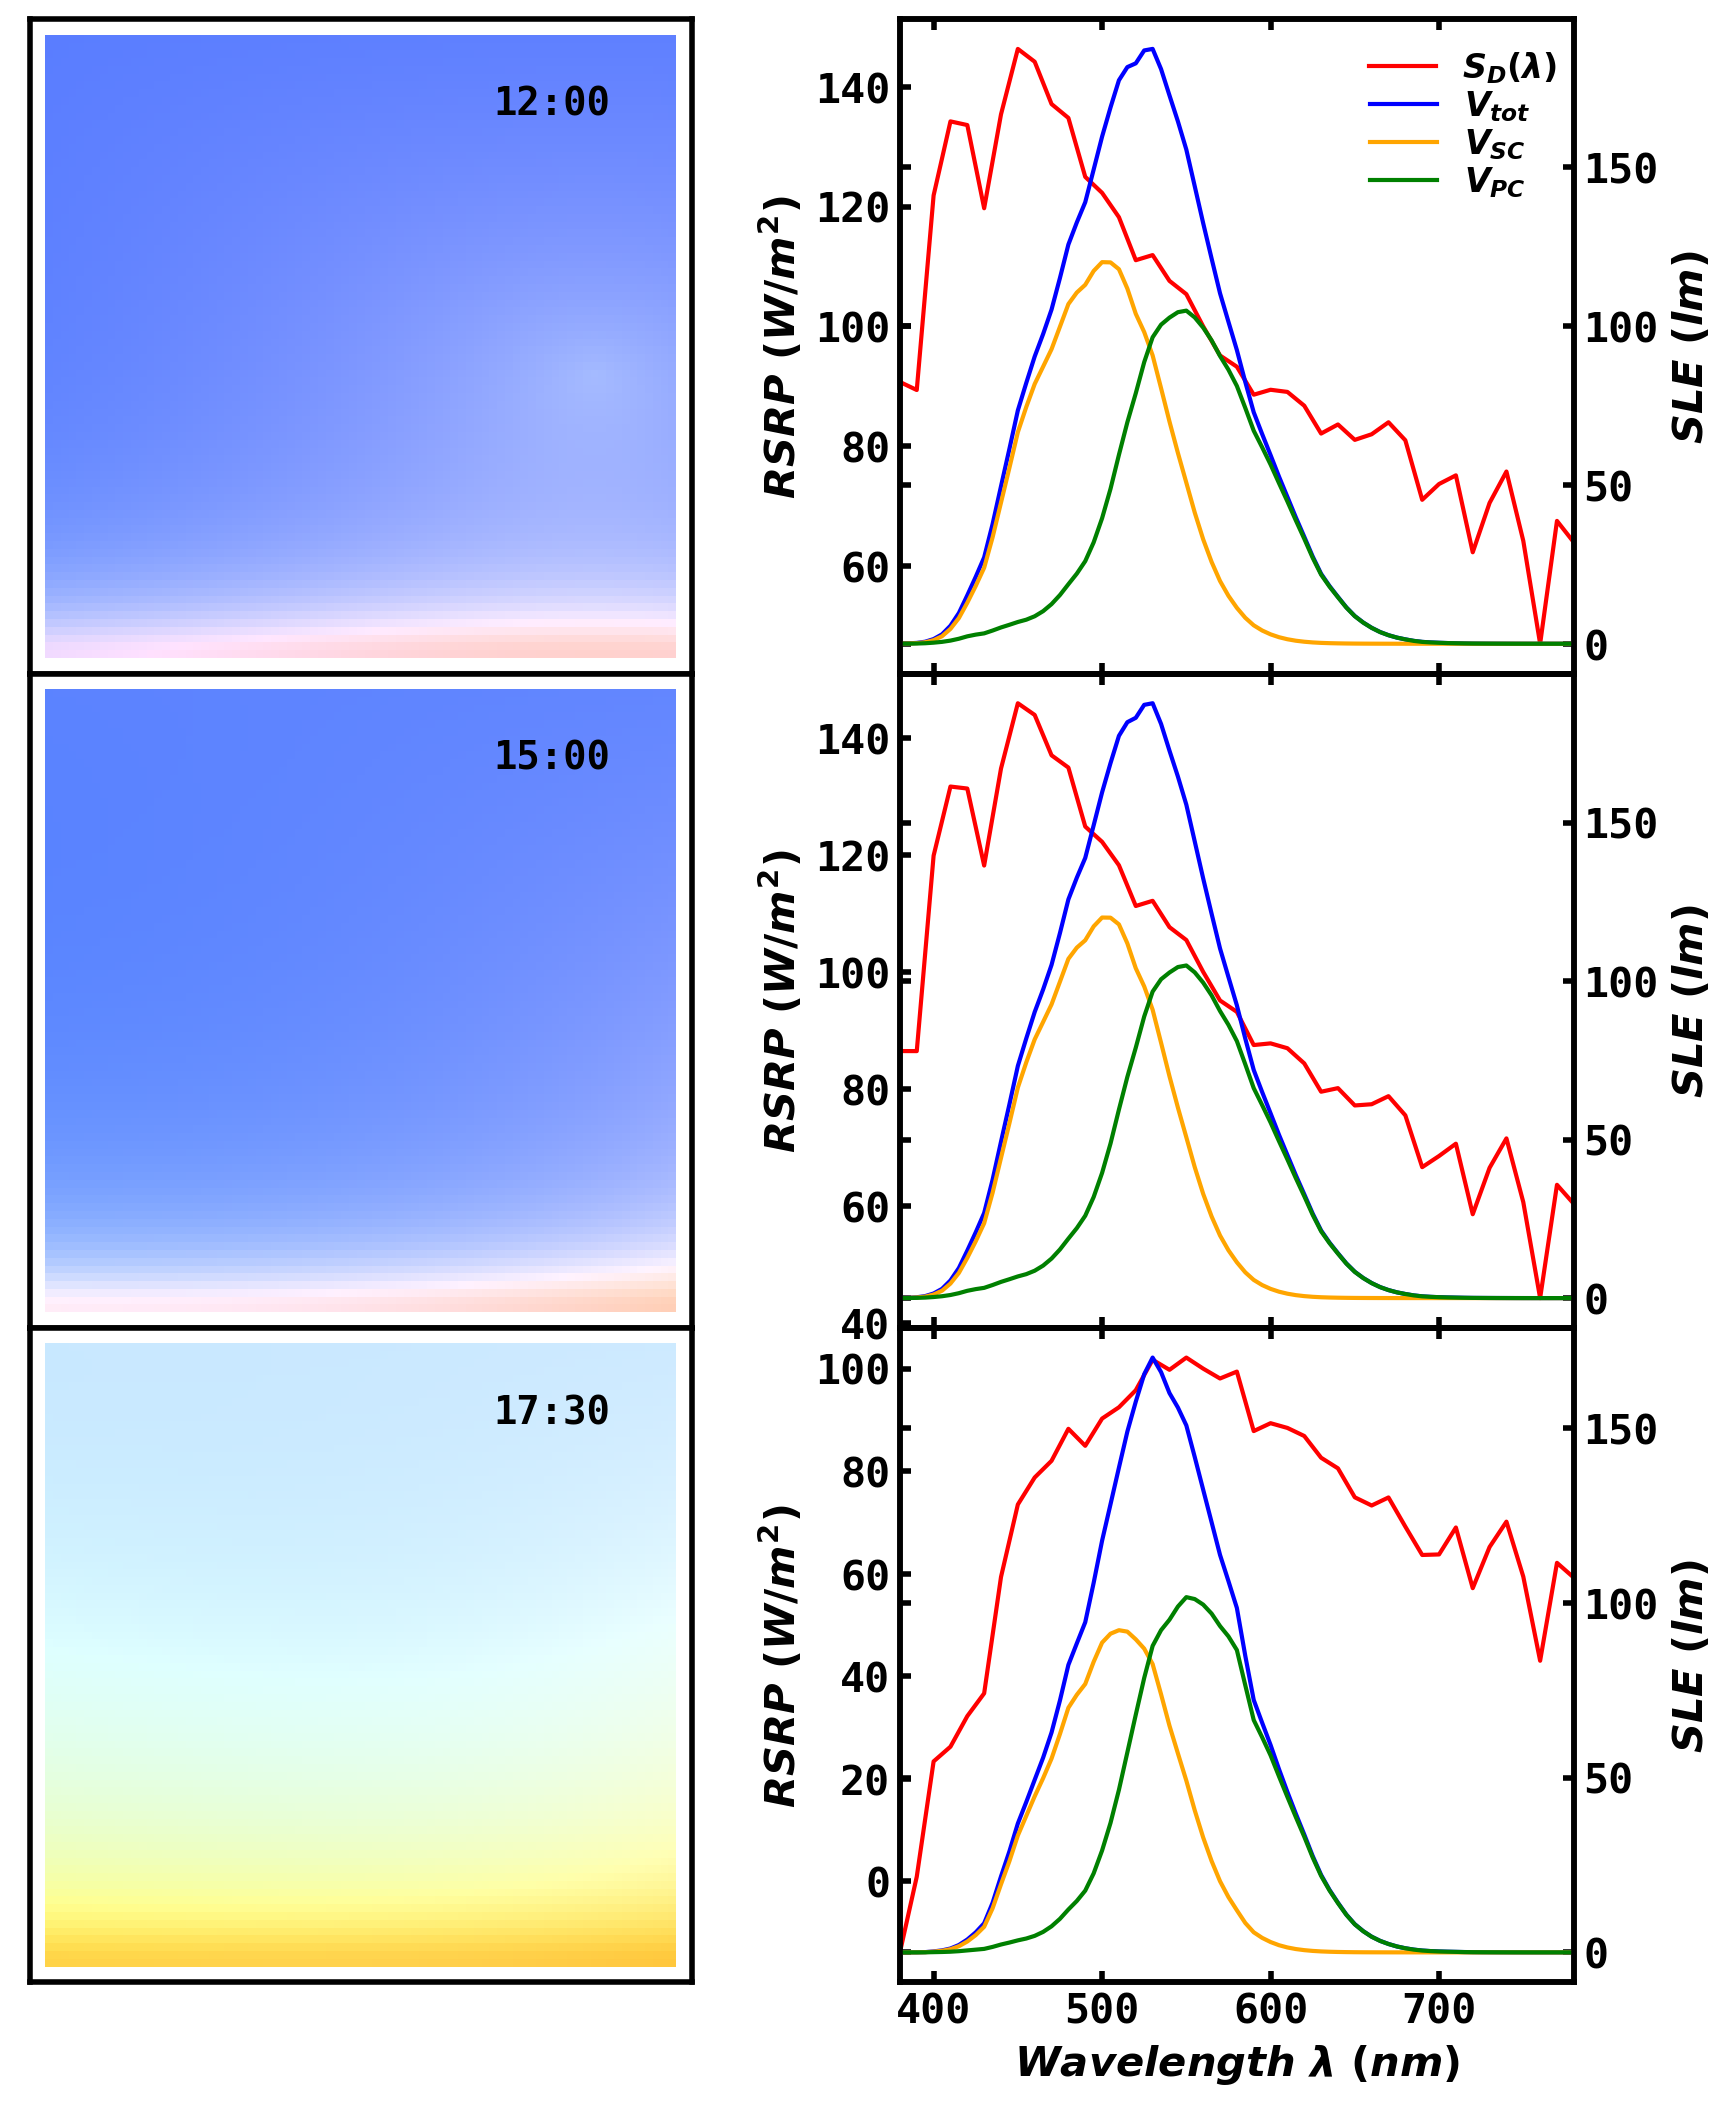

In [22]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(10, 13), dpi=100)
fig.set_facecolor("white")
plt.rc(group="font", family="monospace", weight="bold", size=15)
plt.rc(group="lines", linewidth=1.5)
plt.rc(group="axes", linewidth=2)

city = "Ankara"
alt, tur = 25, 2
lat = city_latitude["Ankara"]
Theta_v_range = (10, 89)   # (zenith=0, horizon=90)
Phi_v_range   = (-70, 10) # (east=-90, south=0, west=90, north=-180)
xaxis_limit, yaxis_limit = (-2, 83), (-81, 3)

Theta_v = 80
Phi_v   = 0

day = dt.datetime(2023, 10, 29)
moment = [dt.timedelta(minutes=60* 12),
          dt.timedelta(minutes=60* 15),
          dt.timedelta(minutes=60* 17.5)]

#====================== 1. COL ======================#
#---------------------- UPPER -----------------------#
ax1 = plt.subplot(321)
time = day + moment[0]
patch_colors = panoramic_sky_view(time,city,alt,tur,Theta_v_range,Phi_v_range)

theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])
n = (theta_difference+1)*(phi_difference+1)
for i in range(n):
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=patch_colors[i])
        ax1.add_patch(patch)
ax1.set_aspect("equal")
ax1.set_xlim(xaxis_limit)
ax1.set_ylim(yaxis_limit)
ax1.set_xticks([])
ax1.set_yticks([])
seconds = moment[0].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax1.text(0.7, 0.9, "%02i:%02i" % (minutes,seconds), transform=ax1.transAxes, fontsize=14, verticalalignment='top')
#ax1.text(0.1, 0.9, "(a)", transform=ax1.transAxes, fontsize=14, verticalalignment='top', bbox=props)


#---------------------- MIDDLE ----------------------#
ax2 = plt.subplot(323)
time = day + moment[1]
patch_colors = panoramic_sky_view(time,city,alt,tur,Theta_v_range,Phi_v_range)

theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])
n = (theta_difference+1)*(phi_difference+1)
for i in range(n):
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=patch_colors[i])
        ax2.add_patch(patch)
ax2.set_aspect("equal")
ax2.set_xlim(xaxis_limit)
ax2.set_ylim(yaxis_limit)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_facecolor('white')
seconds = moment[1].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax2.text(0.7, 0.9, "%02i:%02i" % (minutes,seconds), transform=ax2.transAxes, fontsize=14, verticalalignment='top')
#ax2.text(0.1, 0.9, "(b)", transform=ax2.transAxes, fontsize=14, verticalalignment='top', bbox=props)


#---------------------- LOWER ----------------------#
ax3 = plt.subplot(325)
time = day + moment[2]
patch_colors = panoramic_sky_view(time,city,alt,tur,Theta_v_range,Phi_v_range)

theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])
n = (theta_difference+1)*(phi_difference+1)
for i in range(n):
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=patch_colors[i])
        ax3.add_patch(patch)
ax3.set_aspect("equal")
ax3.set_xlim(xaxis_limit)
ax3.set_ylim(yaxis_limit)
ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_facecolor('white')
seconds = moment[2].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax3.text(0.7, 0.9, "%02i:%02i" % (minutes,seconds), transform=ax3.transAxes, fontsize=14, verticalalignment='top')
#ax3.text(0.1, 0.9, "(c)", transform=ax3.transAxes, fontsize=14, verticalalignment='top', bbox=props)


#====================== 2. COL ======================#
S_d_1, V_sc_1, V_pc_1 = vision_at_a_moment(day+moment[0],lat,alt,tur,Theta_v,Phi_v)
S_d_2, V_sc_2, V_pc_2 = vision_at_a_moment(day+moment[1],lat,alt,tur,Theta_v,Phi_v)
S_d_3, V_sc_3, V_pc_3 = vision_at_a_moment(day+moment[2],lat,alt,tur,Theta_v,Phi_v)

#---------------------- UPPER -----------------------#
xlim = (380, 780)
ax4 = plt.subplot(322)
ax4.plot(lam, S_d_1,  color="r", label="$S_D(\lambda)$")
ax4.set_xlim(380, 790)
ax4.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax4.set_xticklabels([])
ax4.set_ylabel(r"$RSRP \ (W/m^2)$", weight="bold")
ax4.legend(loc=1, bbox_to_anchor=(1.02, 1), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

ax4r = ax4.twinx()
V_tot_1 = V_sc_1 + V_pc_1
ax4r.plot(lam, V_tot_1,  color="blue", label="$V_{tot}$")
ax4r.plot(lam, V_sc_1,  color="orange", label="$V_{SC}$")
ax4r.plot(lam, V_pc_1,  color="green", label="$V_{PC}$")
ax4r.set_xlim(*xlim)
ax4r.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax4r.set_xticklabels([])
ax4r.set_ylabel(r"$SLE \ (lm)$", weight="bold")
ax4r.legend(loc=1, bbox_to_anchor=(0.98, 0.94), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

#---------------------- MIDDLE ----------------------#
ax5 = plt.subplot(324)
ax5.plot(lam, S_d_2,  color="r", label="$S_D(\lambda)$")
ax5.set_xlim(*xlim)
ax5.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax5.set_xticklabels([])
#ax5.set_xlabel(r"$Wavelength \ \lambda \ (nm)$", weight="bold")
ax5.set_ylabel(r"$RSRP \ (W/m^2)$", weight="bold")
#ax5.legend(loc=1, bbox_to_anchor=(1.013, 0.99), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

ax5r = ax5.twinx()
V_tot_2 = V_sc_2 + V_pc_2
ax5r.plot(lam, V_tot_2,  color="blue", label="$V_{tot}$")
ax5r.plot(lam, V_sc_2,  color="orange", label="$V_{SC}$")
ax5r.plot(lam, V_pc_2,  color="green", label="$V_{PC}$")
ax5r.set_xlim(*xlim)
ax5r.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax5r.set_xticklabels([])
ax5r.set_ylabel(r"$SLE \ (lm)$", weight="bold")
#ax5r.legend(loc=1, bbox_to_anchor=(0.98, 0.94), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

#---------------------- LOWER ----------------------#
ax6 = plt.subplot(326)
ax6.plot(lam, S_d_3,  color="r", label="$S_D(\lambda)$")
ax6.set_xlim(*xlim)
ax6.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax6.set_xlabel(r"$Wavelength \ \lambda \ (nm)$", weight="bold")
ax6.set_ylabel(r"$RSRP \ (W/m^2)$", weight="bold")
#ax6.legend(loc=1, bbox_to_anchor=(1.013, 0.99), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

ax6r = ax6.twinx()
V_tot_3 = V_sc_3 + V_pc_3
ax6r.plot(lam, V_tot_3,  color="blue", label="$V_{tot}$")
ax6r.plot(lam, V_sc_3,  color="orange", label="$V_{SC}$")
ax6r.plot(lam, V_pc_3,  color="green", label="$V_{PC}$")
ax5r.set_xlim(*xlim)
ax6r.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax6r.set_ylabel(r"$SLE \ (lm)$", weight="bold")
#ax6r.legend(loc=1, bbox_to_anchor=(0.98, 0.94), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)


plt.subplots_adjust(wspace=0.3, hspace=0)
plt.show()